<center><h1>Zhao_Yibo_HW8</h1></center>

Name: Zhao Yibo
<br>
Github Username: Artmu-bo
<br>
USC ID: 5635641435

## 1. Supervised, Semi-Supervised, and Unsupervised Learning

Import packages

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.svm import LinearSVC
from sklearn.cluster import KMeans, SpectralClustering
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix)
from joblib import Parallel, delayed

### (a) Download the Breast Cancer Wisconsin (Diagnostic) Data Set

In [2]:
wdbc = pd.read_csv('../data/wdbc.data', header=None)
X_bc = wdbc.iloc[:, 2:].values
y_bc = (wdbc[1] == 'M').astype(int).values   # Malignant = 1 (positive class), Benign = 0
print(X_bc.shape, np.bincount(y_bc))

(569, 30) [357 212]


### (b) Monte-Carlo Simulation

#### (i) Supervised Learning

In [3]:
# function preperation: data split, scoring, and plotting
M = 30

def split_scale(seed):
    """Stratified 80/20 split (20% of each class in test), then standardize using train statistics."""
    X_tr, X_te, y_tr, y_te = train_test_split(X_bc, y_bc, test_size=0.2, stratify=y_bc, random_state=seed)
    scaler = StandardScaler().fit(X_tr)
    return scaler.transform(X_tr), scaler.transform(X_te), y_tr, y_te

def l1_svm_cv(X, y):
    """L1-penalized linear SVM; penalty parameter C chosen by 5-fold stratified CV."""
    svm = LinearSVC(penalty='l1', loss='squared_hinge', dual=False, max_iter=10000, random_state=0)
    gs = GridSearchCV(svm, {'C': C_GRID}, cv=StratifiedKFold(5, shuffle=True, random_state=0))
    return gs.fit(X, y).best_estimator_

def get_scores(y, y_pred, score):
    """Accuracy, precision, recall, F1 (positive = malignant) and AUC (uses a continuous score)."""
    return [accuracy_score(y, y_pred), precision_score(y, y_pred, zero_division=0),
            recall_score(y, y_pred), f1_score(y, y_pred), roc_auc_score(y, score)]

def summarize(train_list, test_list):
    """Average the M runs into one table: rows = train/test, columns = 5 metrics."""
    cols = ['Accuracy', 'Precision', 'Recall', 'F1', 'AUC']
    return pd.DataFrame([np.mean(train_list, axis=0), np.mean(test_list, axis=0)],
                        index=['Train', 'Test'], columns=cols).round(4)

def plot_one_run(title, y_tr, s_tr, p_tr, y_te, s_te, p_te):
    """ROC curves (train & test) in one figure, and print both confusion matrices."""
    plt.figure(figsize=(5, 4))
    for name, y, s in [('Train', y_tr, s_tr), ('Test', y_te, s_te)]:
        fpr, tpr, _ = roc_curve(y, s)
        plt.plot(fpr, tpr, label=f'{name} (AUC = {roc_auc_score(y, s):.3f})')
    plt.plot([0, 1], [0, 1], 'k--', lw=0.8)
    plt.xlabel('False Positive Rate'); plt.ylabel('True Positive Rate')
    plt.title(f'ROC – {title} (one run)'); plt.legend(); plt.show()
    print('Confusion matrix – Train (rows = true B/M, cols = predicted B/M):\n', confusion_matrix(y_tr, p_tr))
    print('Confusion matrix – Test:\n', confusion_matrix(y_te, p_te))

In [4]:
# Learned from footnote 4: train L1-SVMs with very small/large C on one training set, then keep the usable C values for the CV grid
X_tr, X_te, y_tr, y_te = split_scale(0)
C_try = np.logspace(-4, 2, 13)                       # 10^-4 ... 10^2, half-decade steps
acc = []
for C in C_try:
    svm = LinearSVC(penalty='l1', loss='squared_hinge', dual=False, C=C, max_iter=10000, random_state=0).fit(X_tr, y_tr)
    acc.append(svm.score(X_tr, y_tr))
    print(f'C = {C:.4f}   train accuracy = {acc[-1]:.3f}   non-zero weights = {np.sum(svm.coef_ != 0)}')
acc = np.array(acc)
C_GRID = C_try[(acc >= 0.7) & (acc < 1.0)]   # keep C with train accuracy >= 70% but not yet 100%
print('C_GRID used for 5-fold CV:', C_GRID.round(4))

C = 0.0001   train accuracy = 0.626   non-zero weights = 0
C = 0.0003   train accuracy = 0.626   non-zero weights = 0
C = 0.0010   train accuracy = 0.626   non-zero weights = 0
C = 0.0032   train accuracy = 0.927   non-zero weights = 3
C = 0.0100   train accuracy = 0.976   non-zero weights = 6
C = 0.0316   train accuracy = 0.987   non-zero weights = 9
C = 0.1000   train accuracy = 0.991   non-zero weights = 11
C = 0.3162   train accuracy = 0.991   non-zero weights = 15
C = 1.0000   train accuracy = 0.993   non-zero weights = 19
C = 3.1623   train accuracy = 0.993   non-zero weights = 26
C = 10.0000   train accuracy = 1.000   non-zero weights = 26
C = 31.6228   train accuracy = 1.000   non-zero weights = 27
C = 100.0000   train accuracy = 1.000   non-zero weights = 27
C_GRID used for 5-fold CV: [0.0032 0.01   0.0316 0.1    0.3162 1.     3.1623]


C chosen by CV (value: number of runs): {0.032: 14, 0.1: 11, 0.316: 4, 1.0: 1}


,Accuracy,Precision,Recall,F1,AUC
Train,0.9841,0.9914,0.9659,0.9784,0.9967
Test,0.9632,0.9688,0.9310,0.9489,0.9929


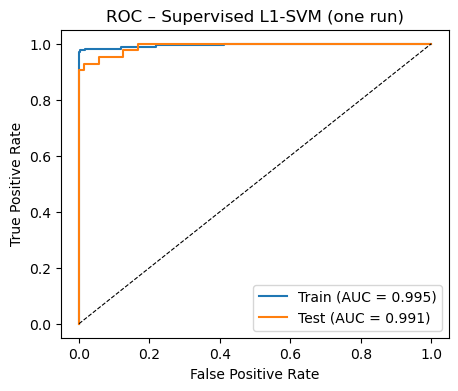

Confusion matrix – Train (rows = true B/M, cols = predicted B/M):
 [[284   1]
 [  5 165]]
Confusion matrix – Test:
 [[68  4]
 [ 3 39]]


In [5]:
#Supervised learning: L1-SVM on the full labeled training set, M = 30 runs
sup_tr, sup_te, sup_C = [], [], []
for run in range(M):
    X_tr, X_te, y_tr, y_te = split_scale(run)
    svm = l1_svm_cv(X_tr, y_tr)
    sup_C.append(svm.C)
    sup_tr.append(get_scores(y_tr, svm.predict(X_tr), svm.decision_function(X_tr)))
    sup_te.append(get_scores(y_te, svm.predict(X_te), svm.decision_function(X_te)))
    if run == 0:   # keep one run for the ROC curve and confusion matrices
        one = (y_tr, svm.decision_function(X_tr), svm.predict(X_tr),
               y_te, svm.decision_function(X_te), svm.predict(X_te))

print('C chosen by CV (value: number of runs):', pd.Series(sup_C).round(3).value_counts().sort_index().to_dict())
sup_table = summarize(sup_tr, sup_te)
display(sup_table)
plot_one_run('Supervised L1-SVM', *one)

**Interpretation:** The L1-SVM works very well: average test accuracy 0.963, AUC 0.993. Test scores are slightly below training scores, as expected. Recall (0.931) is lower than precision (0.969), so most errors are malignant tumors predicted as benign.

**C range:** Following footnote 4 (though footnote4 it's not for this question, I think they are dealing with the same thing here), I drop C values with train accuracy below 70%. I also drop upper C values that fit the training set perfectly (C ≥ 10, train accuracy 1.000), since larger C might memorize the training data(overfit) and cause convergence problems on the smaller CV folds. The remaining 7 values (0.003–3.16, half-decade steps) form the CV grid. CV never picked an edge value in the 30 runs, so the range is wide enough.

#### (ii) Semi-Supervised Learning/ Self-training

##### (A)

In [6]:
# Split training set into 50% labeled / 50% unlabeled (per class), then fit an L1-SVM with 5-fold CV on the labeled half
def initial_svm(seed):
    X_tr, X_te, y_tr, y_te = split_scale(seed)
    X_L, X_U, y_L, _ = train_test_split(X_tr, y_tr, train_size=0.5, stratify=y_tr, random_state=seed)  # true labels of X_U are discarded
    return l1_svm_cv(X_L, y_L), X_L, y_L, X_U, X_tr, y_tr, X_te, y_te

svm0, X_L0, y_L0, X_U0, *_ = initial_svm(0)
print(f'Run 0: {len(y_L0)} labeled (B={np.sum(y_L0 == 0)}, M={np.sum(y_L0 == 1)}), {len(X_U0)} unlabeled; C chosen by CV = {svm0.C:.3f}')

Run 0: 227 labeled (B=142, M=85), 228 unlabeled; C chosen by CV = 0.032


In run 0, 227 training points (50% of each class) are labeled and 228 are unlabeled; the L1-SVM trained on the labeled half chose **C = 0.032** by 5-fold CV.

##### (B)

,Accuracy,Precision,Recall,F1,AUC
Train,0.9785,0.9849,0.9576,0.9709,0.9949
Test,0.9632,0.9685,0.9317,0.9491,0.9917


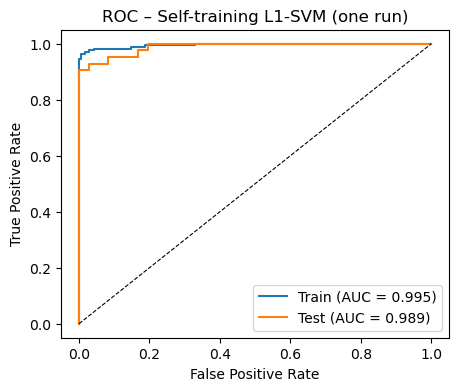

Confusion matrix – Train (rows = true B/M, cols = predicted B/M):
 [[285   0]
 [  9 161]]
Confusion matrix – Test:
 [[70  2]
 [ 3 39]]


In [7]:
# Self-training: repeatedly add the unlabeled point farthest from the hyperplane with the SVM's own label, retrain; M = 30 runs
def self_train(svm, X_L, y_L, X_U):
    X_L, y_L, X_U = X_L.copy(), y_L.copy(), X_U.copy()
    while len(X_U) > 0:
        dist = np.abs(svm.decision_function(X_U)) / np.linalg.norm(svm.coef_)   # distance = |w·x + b| / ||w||
        i = np.argmax(dist)                                                     # most confident point
        X_L = np.vstack([X_L, X_U[i]])
        y_L = np.append(y_L, svm.predict(X_U[i:i + 1]))                         # SVM's label, not the true one
        X_U = np.delete(X_U, i, axis=0)
        svm = LinearSVC(penalty='l1', loss='squared_hinge', dual=False, C=svm.C, max_iter=10000, random_state=0).fit(X_L, y_L)
    return svm

semi_tr, semi_te = [], []
for run in range(M):
    svm, X_L, y_L, X_U, X_tr, y_tr, X_te, y_te = initial_svm(run)
    svm = self_train(svm, X_L, y_L, X_U)
    semi_tr.append(get_scores(y_tr, svm.predict(X_tr), svm.decision_function(X_tr)))   # evaluated with TRUE training labels
    semi_te.append(get_scores(y_te, svm.predict(X_te), svm.decision_function(X_te)))
    if run == 0:
        one = (y_tr, svm.decision_function(X_tr), svm.predict(X_tr),
               y_te, svm.decision_function(X_te), svm.predict(X_te))

semi_table = summarize(semi_tr, semi_te)
display(semi_table)
plot_one_run('Self-training L1-SVM', *one)

**Interpretation:** In each run, 227 training points are labeled (50% of each class) and 228 are unlabeled. C is chosen once by CV in (A) and kept fixed, because the added labels are the SVM's own guesses and may be wrong (we have learned in class that early mistakes could reinforce themselves). Training scores use the true labels of the full training set.

With only half the labels, self-training matches the supervised SVM: test accuracy 0.963 (same), AUC 0.992 (vs 0.993).

#### (iii) Unsupervised Learning

##### (A)

In [8]:
# K-means (k=2) on each of the 30 training sets: 50 single random starts vs. KMeans(n_init=50)
rows = []
for run in range(M):
    X_tr, X_te, y_tr, y_te = split_scale(run)
    single = np.array([KMeans(2, init='random', n_init=1, random_state=s).fit(X_tr).inertia_ for s in range(50)])
    best = KMeans(2, init='random', n_init=50, random_state=0).fit(X_tr).inertia_
    rows.append([run, len(np.unique(single.round(1))), np.sum(single > 1.05 * single.min()), single.min(), single.max(), best])
res = pd.DataFrame(rows, columns=['run', 'distinct WCV', 'bad starts', 'lowest WCV', 'highest WCV', 'n_init=50 WCV']).round(1)
print(res[res['bad starts'] > 0].to_string(index=False))
print('runs with a bad local minimum:', (res['bad starts'] > 0).sum(), '| bad starts in total:', res['bad starts'].sum(), 'of', 50 * M)
print('n_init=50 returned the lowest WCV in every run:', bool(np.all(res['n_init=50 WCV'] <= res['lowest WCV'] + 0.1)))

 run  distinct WCV  bad starts  lowest WCV  highest WCV  n_init=50 WCV
  10             5           1      9232.7      12160.7         9232.7
  11             6           1      9361.9      13260.0         9361.9
  15             2           1      9317.3      13146.4         9317.3
  21             5           1      9156.0      13260.7         9156.0
runs with a bad local minimum: 4 | bad starts in total: 4 of 1500
n_init=50 returned the lowest WCV in every run: True


**How to make sure not trapped in a local minimum:** 
<br>- I avoid this by **running K-means from many random starts and keeping the solution with the lowest WCV**: `KMeans(init='random', n_init=50)` does this, and it returned the lowest WCV in all 30 training sets. 
<br>- The table checks all 30 training sets: for each one, I ran K-means 50 times with a single random start and compared the results with `KMeans(n_init=50)`. Bad local minima are easy to spot: almost all starts end within 0.1% of the lowest WCV, but in 4 of the 30 training sets one start got trapped at a WCV **30–45% higher** (e.g. 13260 vs 9362 in run 11).

##### (B) & (C)

,Accuracy,Precision,Recall,F1,AUC
Train,0.9102,0.9238,0.8282,0.8732,0.9749
Test,0.9053,0.9096,0.8262,0.8647,0.9719


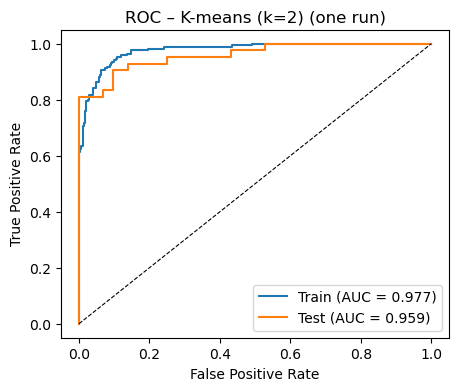

Confusion matrix – Train (rows = true B/M, cols = predicted B/M):
 [[277   8]
 [ 33 137]]
Confusion matrix – Test:
 [[65  7]
 [ 7 35]]


In [9]:
# K-means as a classifier: label each cluster by majority vote of the 30 points closest to its center; M = 30 runs
def softmax_score(dist, cluster_label):
    """P(malignant): softmax of negative distances to the 2 centers, summed over clusters labeled malignant."""
    w = np.exp(-dist) / np.exp(-dist).sum(axis=1, keepdims=True)
    return w[:, cluster_label == 1].sum(axis=1)

def kmeans_classify(km, cluster_label, X):
    dist = km.transform(X)                                   # distance of each point to each center
    return cluster_label[dist.argmin(axis=1)], softmax_score(dist, cluster_label)

km_tr, km_te = [], []
for run in range(M):
    X_tr, X_te, y_tr, y_te = split_scale(run)
    km = KMeans(2, init='random', n_init=50, random_state=run).fit(X_tr)   # labels are NOT used here
    dist_tr = km.transform(X_tr)
    cluster_label = np.array([np.bincount(y_tr[np.argsort(dist_tr[:, k])[:30]], minlength=2).argmax() for k in range(2)])
    p_tr, s_tr = kmeans_classify(km, cluster_label, X_tr)    # (B) training data
    p_te, s_te = kmeans_classify(km, cluster_label, X_te)    # (C) test data: nearest center
    km_tr.append(get_scores(y_tr, p_tr, s_tr))
    km_te.append(get_scores(y_te, p_te, s_te))
    if run == 0:
        one = (y_tr, s_tr, p_tr, y_te, s_te, p_te)

km_table = summarize(km_tr, km_te)
display(km_table)
plot_one_run('K-means (k=2)', *one)

**Interpretation:** Each cluster is labeled by majority vote of the 30 training points closest to its center. "Train" = (B), "Test" = (C), where test points take the label of their nearest center. AUC uses a softmax of the distances to the two centers (footnote 2).

K-means reaches about 0.91 accuracy, below the SVMs (0.96). Recall is low (0.83): many malignant tumors land in the benign cluster, because K-means groups points by distance and never sees the true class boundary. Train and test scores are close because no labels were used for fitting.

#### (iv) Spectral Clustering

Smaller cluster size per gamma: {1.0: 2, 0.5623: 2, 0.3162: 2, 0.1778: 2, 0.1: 2, 0.0562: 2, 0.0316: 2, 0.0178: 128, 0.01: 153, 0.0056: 171, 0.0032: 171, 0.0018: 184, 0.001: 189, 0.0006: 189, 0.0003: 189, 0.0002: 189, 0.0001: 189, 0.0: 189}
Target p = 212; best gamma = 0.0010

gamma = 1.0000


,Accuracy,Precision,Recall,F1,AUC
Train,0.6300,1.0000,0.0096,0.0190,0.5048
Test,0.6348,0.3667,0.0087,0.0171,0.5044


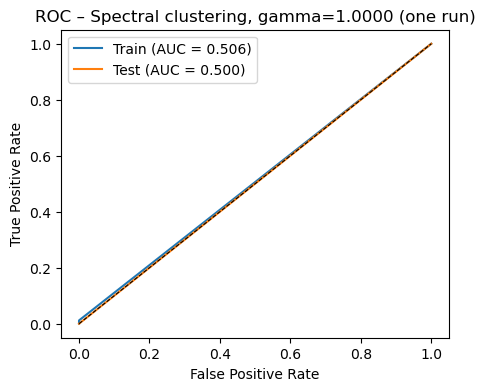

Confusion matrix – Train (rows = true B/M, cols = predicted B/M):
 [[285   0]
 [168   2]]
Confusion matrix – Test:
 [[72  0]
 [42  0]]

gamma = 0.0010


,Accuracy,Precision,Recall,F1,AUC
Train,0.9101,0.9291,0.8224,0.8723,0.8924
Test,0.9073,0.9195,0.8222,0.8668,0.8896


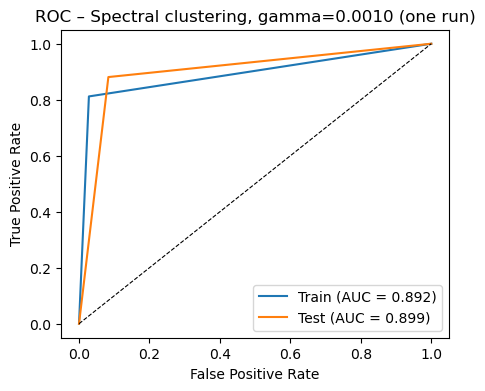

Confusion matrix – Train (rows = true B/M, cols = predicted B/M):
 [[277   8]
 [ 32 138]]
Confusion matrix – Test:
 [[66  6]
 [ 5 37]]


In [10]:
# Spectral clustering (RBF kernel) on train+test together; clusters labeled by majority vote of ALL training points in them
p, n = np.sum(y_bc == 1), np.sum(y_bc == 0)          # 212 malignant, 357 benign
X_tr, X_te, y_tr, y_te = split_scale(0)
gammas = np.logspace(0, -6, 25)  
sizes = [np.bincount(SpectralClustering(2, gamma=g, random_state=0).fit_predict(np.vstack([X_tr, X_te]))).min() for g in gammas]
best_gamma = gammas[np.argmin(np.abs(np.array(sizes) - p))]
print('Smaller cluster size per gamma:', {round(float(g), 4): int(s) for g, s in zip(gammas, sizes)})
print(f'Target p = {p}; best gamma = {best_gamma:.4f}')

def spectral_runs(gamma):
    sp_tr, sp_te = [], []
    for run in range(M):
        X_tr, X_te, y_tr, y_te = split_scale(run)
        lab = SpectralClustering(2, gamma=gamma, random_state=run).fit_predict(np.vstack([X_tr, X_te]))
        lab_tr, lab_te = lab[:len(y_tr)], lab[len(y_tr):]
        # fraction of malignant training points in each cluster (empty cluster -> 0, i.e. benign)
        frac = np.array([y_tr[lab_tr == k].mean() if np.any(lab_tr == k) else 0.0 for k in range(2)])
        s_tr, s_te = frac[lab_tr], frac[lab_te]                  # score for ROC: vary the majority-vote threshold
        p_tr, p_te = (s_tr > 0.5).astype(int), (s_te > 0.5).astype(int)
        sp_tr.append(get_scores(y_tr, p_tr, s_tr))
        sp_te.append(get_scores(y_te, p_te, s_te))
        if run == 0:
            one = (y_tr, s_tr, p_tr, y_te, s_te, p_te)
    return summarize(sp_tr, sp_te), one

sp_tables = {}
for g in [1.0, best_gamma]:
    table, one = spectral_runs(g)
    sp_tables[g] = table
    print(f'\ngamma = {g:.4f}'); display(table)
    plot_one_run(f'Spectral clustering, gamma={g:.4f}', *one)

**Method:** Spectral clustering has no `predict`, so it cannot label new points. Following the transductive idea in Lesson 9, we run `fit_predict` on training + test points together, but only use training labels: each cluster gets the majority label of its training points (footnote 3). The ROC varies the majority-vote threshold.

**gamma = 1 fails:** In 30 standardized dimensions, gamma = 1 makes almost all similarities ≈ 0, so it only splits off 2 outliers (567 vs 2). Everything is predicted benign: accuracy 0.63, AUC ≈ 0.5.

**Better gamma:** I searched gamma from 1 down to 10⁻⁶. No gamma gives exactly 357 vs 212. The closest is 380 vs 189, and every gamma from 0.001 down to 10⁻⁶ gives this same split, so no smaller gamma does better. Among these ties I keep the largest, gamma = 0.001, because a smaller gamma makes all similarities close to 1 and the kernel carries less information. 
<br>I report both gamma = 1 and gamma = 0.001. With gamma = 0.001, test accuracy is 0.907, close to K-means. AUC is lower (0.89) because all points in a cluster share one score, so the ROC has only one corner.

#### (v) Compare

In [11]:
compare = pd.concat({'Supervised L1-SVM': sup_table,
                     'Self-training L1-SVM': semi_table,
                     'K-means (k=2)': km_table,
                     'Spectral (gamma=1)': sp_tables[1.0],
                     f'Spectral (gamma={best_gamma:.3f})': sp_tables[best_gamma]})
display(compare)

Accuracy  Precision  Recall      F1     AUC
Supervised L1-SVM      Train    0.9841     0.9914  0.9659  0.9784  0.9967
                       Test     0.9632     0.9688  0.9310  0.9489  0.9929
Self-training L1-SVM   Train    0.9785     0.9849  0.9576  0.9709  0.9949
                       Test     0.9632     0.9685  0.9317  0.9491  0.9917
K-means (k=2)          Train    0.9102     0.9238  0.8282  0.8732  0.9749
                       Test     0.9053     0.9096  0.8262  0.8647  0.9719
Spectral (gamma=1)     Train    0.6300     1.0000  0.0096  0.0190  0.5048
                       Test     0.6348     0.3667  0.0087  0.0171  0.5044
Spectral (gamma=0.001) Train    0.9101     0.9291  0.8224  0.8723  0.8924
                       Test     0.9073     0.9195  0.8222  0.8668  0.8896

**Ranking:** Supervised ≈ Self-training > Spectral (gamma = 0.001) ≈ K-means >> Spectral (gamma = 1).

**Supervised vs. semi-supervised:** Supervised is **best** on the training set and has the top test AUC (0.993), as expected. But self-training with half the labels is nearly **as good** on the test set (same accuracy 0.963, AUC 0.992). 

**Unsupervised underperforms as expected:** K-means (0.905) and spectral clustering with gamma = 0.001 (0.907) are about 6 points below the SVMs, mainly because recall drops to about 0.82. Clustering groups points by similarity, not by label, so its boundary might not match the true class boundary perfectly. With gamma = 1, spectral clustering fails completely.

## 2. Active Learning Using Support Vector Machines

### (a) Download the banknote authentication Data Set

In [12]:
# Load banknote data; random 472 test / 900 train split; standardize with training-set statistics
bn = pd.read_csv('../data/data_banknote_authentication.txt', header=None)
X_bn, y_bn = bn.iloc[:, :4].values, bn[4].values
X_pool, X_test, y_pool, y_test = train_test_split(X_bn, y_bn, test_size=472, random_state=0)
scaler = StandardScaler().fit(X_pool)
X_pool, X_test = scaler.transform(X_pool), scaler.transform(X_test)
print('Train:', X_pool.shape, np.bincount(y_pool), '| Test:', X_test.shape, np.bincount(y_test))

Train: (900, 4) [500 400] | Test: (472, 4) [262 210]


In [13]:
# Footnote 4: train L1-SVMs with very small/large C on the whole training set; keep C with train accuracy >= 70%
C_try = np.logspace(-4, 1, 11)       # 10^-4 ... 10^1, half-decade steps
acc = []
for C in C_try:
    svm = LinearSVC(penalty='l1', loss='squared_hinge', dual=False, C=C, max_iter=100000, random_state=0).fit(X_pool, y_pool)
    acc.append(svm.score(X_pool, y_pool))
    print(f'C = {C:.4f}   train accuracy = {acc[-1]:.3f}')
C_GRID2 = C_try[np.array(acc) >= 0.7]
print('Range by footnote 4:', [round(float(c), 4) for c in C_GRID2])

# Drop C < 0.1: in a full run with C in {0.001, 0.01, 0.1, 1, 10} in the past, C = 0.01 caused 36 convergence warnings and was never picked by CV; C = 0.001 was picked once (CV tie on a 10-point pool) and gave an all-zero-weight SVM (test error 0.445), so I didn't put them in this version
C_GRID2 = C_GRID2[C_GRID2 >= 0.1]
print('C_GRID2 used for 5-fold CV:', [round(float(c), 4) for c in C_GRID2])

C = 0.0001   train accuracy = 0.556
C = 0.0003   train accuracy = 0.556
C = 0.0010   train accuracy = 0.847
C = 0.0032   train accuracy = 0.866
C = 0.0100   train accuracy = 0.971
C = 0.0316   train accuracy = 0.981
C = 0.1000   train accuracy = 0.982
C = 0.3162   train accuracy = 0.990
C = 1.0000   train accuracy = 0.994
C = 3.1623   train accuracy = 0.994
C = 10.0000   train accuracy = 0.993
Range by footnote 4: [0.001, 0.0032, 0.01, 0.0316, 0.1, 0.3162, 1.0, 3.1623, 10.0]
C_GRID2 used for 5-fold CV: [0.1, 0.3162, 1.0, 3.1623, 10.0]


### (b) Repeat each of the following two procedures 50 times

#### (i) Passive

In [14]:
# Passive learning: add 10 random points at a time; L1 linear SVM with 5-fold CV each time; 50 repetitions

def svm_cv2(X, y):
    svm = LinearSVC(penalty='l1', loss='squared_hinge', dual=False, max_iter=100000, random_state=0)
    gs = GridSearchCV(svm, {'C': C_GRID2}, cv=StratifiedKFold(5, shuffle=True, random_state=0))
    return gs.fit(X, y).best_estimator_

def initial_pool(rng):
    """10 random training points with at least 5 per class, so stratified 5-fold CV is possible."""
    while True:
        idx = rng.choice(len(y_pool), 10, replace=False)
        if np.bincount(y_pool[idx], minlength=2).min() >= 5:
            return idx

def passive(seed):
    rng = np.random.default_rng(seed)
    init = initial_pool(rng)
    order = np.concatenate([init, rng.permutation(np.setdiff1d(np.arange(len(y_pool)), init))])   # random order, no replacement
    return [1 - svm_cv2(X_pool[order[:n]], y_pool[order[:n]]).score(X_test, y_test) for n in range(10, 901, 10)]

passive_err = np.array(Parallel(n_jobs=-1)(delayed(passive)(s) for s in range(50)))   # shape (50, 90)
print('Passive learning test-error matrix:', passive_err.shape)

Passive learning test-error matrix: (50, 90)


#### (ii) Active

In [15]:
# Active learning: add the 10 training points closest to the current hyperplane; 50 repetitions
def active(seed):
    rng = np.random.default_rng(seed)
    labeled, errors = list(initial_pool(rng)), []
    while True:
        svm = svm_cv2(X_pool[labeled], y_pool[labeled])
        errors.append(1 - svm.score(X_test, y_test))
        rest = np.setdiff1d(np.arange(len(y_pool)), labeled)
        if len(rest) == 0:
            return errors
        dist = np.abs(svm.decision_function(X_pool[rest])) / np.linalg.norm(svm.coef_)   # |w·x + b| / ||w||
        labeled += list(rest[np.argsort(dist)[:10]])                                    # 10 most uncertain points

active_err = np.array(Parallel(n_jobs=-1)(delayed(active)(s) for s in range(50)))     # shape (50, 90)
print('Active learning test-error matrix:', active_err.shape)

Active learning test-error matrix: (50, 90)


### (c) Average the 50 test errors

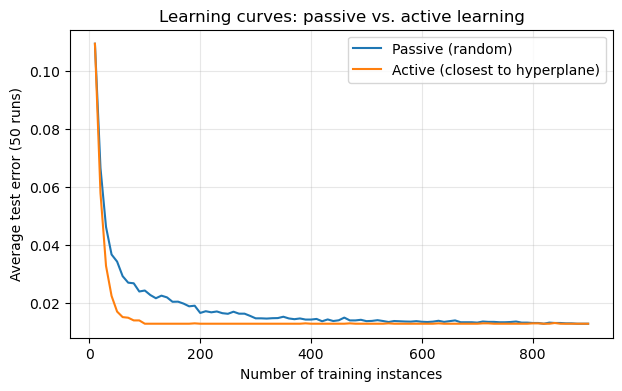

            10      20      30      50      100     200     500     900
Passive  0.1095  0.0666  0.0462  0.0342  0.0242  0.0164  0.0136  0.0127
Active   0.1095  0.0579  0.0327  0.0169  0.0127  0.0127  0.0127  0.0127


In [16]:
# Learning curves: average test error over 50 runs vs number of training instances
n_train = np.arange(10, 901, 10)
plt.figure(figsize=(7, 4))
plt.plot(n_train, passive_err.mean(axis=0), label='Passive (random)')
plt.plot(n_train, active_err.mean(axis=0), label='Active (closest to hyperplane)')
plt.xlabel('Number of training instances'); plt.ylabel('Average test error (50 runs)')
plt.title('Learning curves: passive vs. active learning'); plt.legend(); plt.grid(alpha=0.3); plt.show()
print(pd.DataFrame({'Passive': passive_err.mean(axis=0), 'Active': active_err.mean(axis=0)},
                   index=n_train).loc[[10, 20, 30, 50, 100, 200, 500, 900]].round(4).T)

**C range:** Following footnote 4, the cell after (a) keeps every C with training accuracy ≥ 70% on the whole training set (0.001 to 10; we stop at 10 because accuracy stops improving after C ≈ 1). We then drop C < 0.1: in an earlier full run, C = 0.01 caused 36 convergence warnings and was never selected, and C = 0.001 was selected only once, giving an all-zero-weight SVM. The final grid is {0.1, 0.316, 1, 3.16, 10}.

**Reading the table and curves:** Both curves fall fastest between 10 and 30 points, because with so few labels almost any new point teaches the SVM something. After the first batch, active learning pulls ahead: it labels the points the current SVM is least sure about. By about 100 points the active curve flattens at its final value, because the points that decide the boundary (the future support vectors) are already in the pool, and the points added later lie far from the boundary and no longer change the SVM. <br>The passive curve keeps falling slowly and is not smooth: random batches occasionally hit the region near the boundary, and some batches even shift the boundary slightly the wrong way.

**Conclusion:** Both methods start at the same error (0.11) and end at the same error (0.013), since at 900 points they use the same data. In between, active learning is clearly better: it reaches the final error with about 100 points, while passive learning needs about 800–900.

Points closest to the hyperplane are the ones the SVM is least sure about, and they decide where the boundary goes. Random points are mostly far from the boundary and barely change the SVM. So active learning reaches the same accuracy with far fewer labels.